In [231]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow

In [232]:
df = pd.read_parquet("Sample_Superstore_2019_Clean.parquet", engine="pyarrow")
df.shape

(9993, 20)

In [233]:
df.duplicated().sum()

np.int64(0)

In [234]:
df.isnull().sum()

Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State             0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [235]:
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Day of Week'] = df['Order Date'].dt.day_name()

df['Shipping Duration (Days)'] = (df['Ship Date'] - df['Order Date']).dt.days

cols_to_check = ['Order Date', 'Ship Date', 'Order Year', 'Order Month', 'Order Day of Week', 'Shipping Duration (Days)']
display(df[cols_to_check].head())

,Order Date,Ship Date,Order Year,Order Month,Order Day of Week,Shipping Duration (Days)
0,2018-11-08,2018-11-11,2018,11,Thursday,3
1,2018-11-08,2018-11-11,2018,11,Thursday,3
2,2018-06-12,2018-06-16,2018,6,Tuesday,4
3,2017-10-11,2017-10-18,2017,10,Wednesday,7
4,2017-10-11,2017-10-18,2017,10,Wednesday,7


In [236]:
# Creating the copy of the original DataFrame
df_clean = df.copy()
df_clean.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 9993 entries, 0 to 9992
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Order ID                  9993 non-null   str           
 1   Order Date                9993 non-null   datetime64[us]
 2   Ship Date                 9993 non-null   datetime64[us]
 3   Ship Mode                 9993 non-null   category      
 4   Customer ID               9993 non-null   str           
 5   Customer Name             9993 non-null   str           
 6   Segment                   9993 non-null   str           
 7   Country/Region            9993 non-null   category      
 8   City                      9993 non-null   str           
 9   State                     9993 non-null   category      
 10  Postal Code               9993 non-null   str           
 11  Region                    9993 non-null   category      
 12  Product ID                9993 

In [237]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

cat_cols = ['Ship Mode', 'Segment', 'Country/Region', 'State', 'Region', 'Category', 'Sub-Category']
df[cat_cols] = df[cat_cols].astype('category')

str_cols = ['Order ID', 'Customer ID', 'Customer Name', 'City', 'Postal Code', 'Product ID', 'Product Name']
df[str_cols] = df[str_cols].astype(str)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9993 entries, 0 to 9992
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Order ID                  9993 non-null   str           
 1   Order Date                9993 non-null   datetime64[us]
 2   Ship Date                 9993 non-null   datetime64[us]
 3   Ship Mode                 9993 non-null   category      
 4   Customer ID               9993 non-null   str           
 5   Customer Name             9993 non-null   str           
 6   Segment                   9993 non-null   category      
 7   Country/Region            9993 non-null   category      
 8   City                      9993 non-null   str           
 9   State                     9993 non-null   category      
 10  Postal Code               9993 non-null   str           
 11  Region                    9993 non-null   category      
 12  Product ID                9993 

In [238]:
df_clean.isnull().sum()

Order ID                    0
Order Date                  0
Ship Date                   0
Ship Mode                   0
Customer ID                 0
Customer Name               0
Segment                     0
Country/Region              0
City                        0
State                       0
Postal Code                 0
Region                      0
Product ID                  0
Category                    0
Sub-Category                0
Product Name                0
Sales                       0
Quantity                    0
Discount                    0
Profit                      0
Order Year                  0
Order Month                 0
Order Day of Week           0
Shipping Duration (Days)    0
dtype: int64

In [239]:

df_clean["Order Month"] = df_clean["Order Date"].dt.month_name()
df_clean["Order Year"] = df_clean["Order Date"].dt.year
df_clean["Order Quarter"] = df_clean["Order Date"].dt.quarter
df_clean["Order Day of Week"] = df_clean["Order Date"].dt.day_name()

df_clean["Is Weekend"] = df_clean["Order Date"].dt.dayofweek.isin([5, 6])

df_clean["Shipping Duration (Days)"] = (df_clean["Ship Date"] - df_clean["Order Date"]).dt.days



df_clean["Unit Price"] = df_clean["Sales"] / df_clean["Quantity"]


import numpy as np
df_clean["Profit Margin"] = np.where(df_clean["Sales"] > 0, df_clean["Profit"] / df_clean["Sales"], 0)


bins = [-0.01, 0, 0.2, 0.5, 1]
labels = ["No Discount", "Low (<20%)", "Medium (20-50%)", "High (>50%)"]
df_clean["Discount Bucket"] = pd.cut(df_clean["Discount"], bins=bins, labels=labels)

print("New Features Engineered Successfully!")
display(df_clean[["Order Month", "Shipping Duration (Days)", "Profit Margin", "Discount Bucket"]].head())

New Features Engineered Successfully!


,Order Month,Shipping Duration (Days),Profit Margin,Discount Bucket
0,November,3,0.1600,No Discount
1,November,3,0.3000,No Discount
2,June,4,0.4700,No Discount
3,October,7,-0.4000,Medium (20-50%)
4,October,7,0.1125,Low (<20%)


In [240]:
df_clean["Order Month"] = df_clean["Order Date"].dt.month_name()

Number of orders per month (Calendar Order):


Order Month
January       381
February      300
March         696
April         668
May           735
June          717
July          710
August        706
September    1383
October       819
November     1471
December     1408
Name: count, dtype: int64

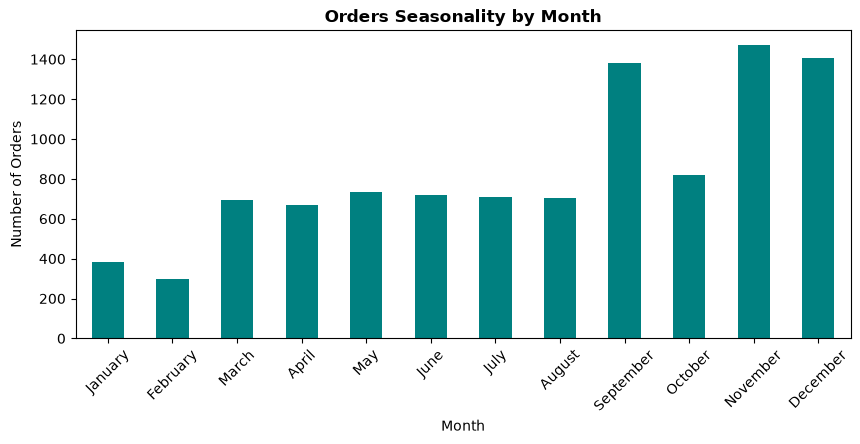

In [241]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load data into memory
df_clean = pd.read_parquet("handoff_data/df_clean.parquet", engine="pyarrow")

# 2. Define the ordering function
def order_by_month(data):
    """Return a calendar-ordered monthly frequency series.
    
    This helper accepts a Series containing month names such as
    "January" ... "December". It counts how often each month
    appears in the data and then re-indexes the result against the standard
    calendar order so the output stays readable and predictable for charts
    and reporting.
    """
    month_order = [
        "January", "February", "March", "April", "May", "June",
        "July", "August", "September", "October", "November", "December"
    ]
    ordered_data = data.value_counts().reindex(month_order)
    
    return ordered_data

# 3. Apply function and plot
monthly_orders = order_by_month(df_clean["Order Month"])

print("Number of orders per month (Calendar Order):")
display(monthly_orders)

plt.figure(figsize=(10, 4))
monthly_orders.plot(kind='bar', color='teal')
plt.title("Orders Seasonality by Month", fontweight='bold')
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

In [242]:
def order_by_month(data):
    """Return a calendar-ordered monthly frequency series.

    This helper accepts a Series containing month names such as
    ``"January"`` ... ``"December"``. It counts how often each month
    appears in the data and then re-indexes the result against the standard
    calendar order so the output stays readable and predictable for charts
    and reporting.
    """
    month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"]
    ordered_data = data.value_counts().reindex(month_order)

    return ordered_data

In [243]:
print(order_by_month(df_clean["Order Month"]))

Order Month
January       381
February      300
March         696
April         668
May           735
June          717
July          710
August        706
September    1383
October       819
November     1471
December     1408
Name: count, dtype: int64


In [244]:
df_clean[["Order Date", "Ship Date"]]

,Order Date,Ship Date
0,2018-11-08,2018-11-11
1,2018-11-08,2018-11-11
2,2018-06-12,2018-06-16
3,2017-10-11,2017-10-18
4,2017-10-11,2017-10-18
...,...,...
9989,2016-01-21,2016-01-23
9990,2019-02-26,2019-03-03
9991,2019-02-26,2019-03-03
9992,2019-02-26,2019-03-03


In [245]:
df_clean["Shipping Days"] = (df_clean["Ship Date"] - df_clean["Order Date"]).dt.days

In [246]:
df_clean["Shipping Days"].mean()

np.float64(3.9580748449069443)

In [247]:
df_clean["Order Date"]

0      2018-11-08
1      2018-11-08
2      2018-06-12
3      2017-10-11
4      2017-10-11
          ...    
9989   2016-01-21
9990   2019-02-26
9991   2019-02-26
9992   2019-02-26
9993   2019-05-04
Name: Order Date, Length: 9994, dtype: datetime64[us]

In [248]:
df_clean["Order Date"].dt.day_name()

0        Thursday
1        Thursday
2         Tuesday
3       Wednesday
4       Wednesday
          ...    
9989     Thursday
9990      Tuesday
9991      Tuesday
9992      Tuesday
9993     Saturday
Name: Order Date, Length: 9994, dtype: str

In [249]:
df_clean["Shipping Days"] = (df_clean["Ship Date"] - df_clean["Order Date"]).dt.days
df_clean.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,...,Order Day of Week,Shipping Duration (Days),Order Quarter,Is Weekend,Unit Price,Profit Margin,Discount Bucket,Shipping Days,Order Weekday,IS Weekend
0,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,130.9800,16.00,No Discount,3,Thursday,False
1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,243.9800,30.00,No Discount,3,Thursday,False
2,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Tuesday,4,2,False,7.3100,47.00,No Discount,4,Tuesday,False
3,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,191.5155,-40.00,Meduim Discount,7,Wednesday,False
4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,11.1840,11.25,Low Discount,7,Wednesday,False


In [250]:

df_clean["Order Weekday"] = df_clean["Order Date"].dt.day_name()
# df_clean["Order Month"] = df_clean["Order Date"].dt.month
df_clean["Order Quarter"] = df_clean["Order Date"].dt.quarter
df_clean["Order Year"] = df_clean["Order Date"].dt.year

In [251]:
df_clean.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,...,Order Day of Week,Shipping Duration (Days),Order Quarter,Is Weekend,Unit Price,Profit Margin,Discount Bucket,Shipping Days,Order Weekday,IS Weekend
0,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,130.9800,16.00,No Discount,3,Thursday,False
1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,243.9800,30.00,No Discount,3,Thursday,False
2,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Tuesday,4,2,False,7.3100,47.00,No Discount,4,Tuesday,False
3,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,191.5155,-40.00,Meduim Discount,7,Wednesday,False
4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,11.1840,11.25,Low Discount,7,Wednesday,False


In [252]:
df_clean["IS Weekend"] = df_clean["Order Date"].dt.day_of_week >= 5
df_clean.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,...,Order Day of Week,Shipping Duration (Days),Order Quarter,Is Weekend,Unit Price,Profit Margin,Discount Bucket,Shipping Days,Order Weekday,IS Weekend
0,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,130.9800,16.00,No Discount,3,Thursday,False
1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,243.9800,30.00,No Discount,3,Thursday,False
2,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Tuesday,4,2,False,7.3100,47.00,No Discount,4,Tuesday,False
3,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,191.5155,-40.00,Meduim Discount,7,Wednesday,False
4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,11.1840,11.25,Low Discount,7,Wednesday,False


In [253]:
df_clean["IS Weekend"].value_counts()


IS Weekend
False    7257
True     2737
Name: count, dtype: int64

In [254]:
df_clean.head()


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,...,Order Day of Week,Shipping Duration (Days),Order Quarter,Is Weekend,Unit Price,Profit Margin,Discount Bucket,Shipping Days,Order Weekday,IS Weekend
0,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,130.9800,16.00,No Discount,3,Thursday,False
1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,243.9800,30.00,No Discount,3,Thursday,False
2,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Tuesday,4,2,False,7.3100,47.00,No Discount,4,Tuesday,False
3,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,191.5155,-40.00,Meduim Discount,7,Wednesday,False
4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,11.1840,11.25,Low Discount,7,Wednesday,False


In [255]:
print(df_clean["Order Date"].dt.day_of_week, df_clean["Order Date"].dt.day_name())

0       3
1       3
2       1
3       2
4       2
       ..
9989    3
9990    1
9991    1
9992    1
9993    5
Name: Order Date, Length: 9994, dtype: int32 0        Thursday
1        Thursday
2         Tuesday
3       Wednesday
4       Wednesday
          ...    
9989     Thursday
9990      Tuesday
9991      Tuesday
9992      Tuesday
9993     Saturday
Name: Order Date, Length: 9994, dtype: str


In [256]:
df_clean["Order Date"].dt.dayofweek

0       3
1       3
2       1
3       2
4       2
       ..
9989    3
9990    1
9991    1
9992    1
9993    5
Name: Order Date, Length: 9994, dtype: int32

In [257]:

df_clean["Is Weekend"] = df_clean["Order Date"].dt.dayofweek >= 5

df_clean[["Order Date", "Ship Date", "Shipping Days", "Order Weekday", "Sales", "Is Weekend"]].head(50)

,Order Date,Ship Date,Shipping Days,Order Weekday,Sales,Is Weekend
0,2018-11-08,2018-11-11,3,Thursday,261.9600,False
1,2018-11-08,2018-11-11,3,Thursday,731.9400,False
2,2018-06-12,2018-06-16,4,Tuesday,14.6200,False
3,2017-10-11,2017-10-18,7,Wednesday,957.5775,False
4,2017-10-11,2017-10-18,7,Wednesday,22.3680,False
5,2016-06-09,2016-06-14,5,Thursday,48.8600,False
6,2016-06-09,2016-06-14,5,Thursday,7.2800,False
7,2016-06-09,2016-06-14,5,Thursday,907.1520,False
8,2016-06-09,2016-06-14,5,Thursday,18.5040,False
9,2016-06-09,2016-06-14,5,Thursday,114.9000,False


In [258]:
weekend_sales_test = df_clean.groupby("Is Weekend").agg(
    total_sales = ("Profit", "mean")
)
weekend_sales_test

,total_sales
Is Weekend,
False,28.974414
True,27.815017


In [259]:
df_clean["Is Weekend"].value_counts()

Is Weekend
False    7257
True     2737
Name: count, dtype: int64

In [260]:
# Numeric transforms -- needed for the discount question (Q2)
df_clean["Unit Price"] = df_clean["Sales"] / df_clean["Quantity"]
df_clean["Profit Margin"] = (df_clean["Profit"] / df_clean["Sales"])*100
df_clean[["Product ID", "Sales", "Unit Price", "Profit Margin"]]

,Product ID,Sales,Unit Price,Profit Margin
0,FUR-BO-10001798,261.9600,130.9800,16.00
1,FUR-CH-10000454,731.9400,243.9800,30.00
2,OFF-LA-10000240,14.6200,7.3100,47.00
3,FUR-TA-10000577,957.5775,191.5155,-40.00
4,OFF-ST-10000760,22.3680,11.1840,11.25
...,...,...,...,...
9989,FUR-FU-10001889,25.2480,8.4160,16.25
9990,FUR-FU-10000747,91.9600,45.9800,17.00
9991,TEC-PH-10003645,258.5760,129.2880,7.50
9992,OFF-PA-10004041,29.6000,7.4000,45.00


<Axes: xlabel='Discount'>

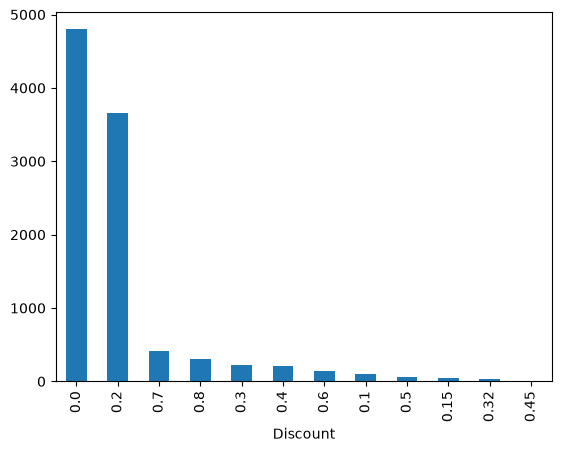

In [261]:
df_clean["Discount"].value_counts().plot(kind='bar')

In [262]:
df_clean["Discount Bucket"] = pd.cut(
    df_clean["Discount"],
    bins= [ -0.01, 0, 0.30, 0.6, 0.8, 1],
    labels= ["No Discount", "Low Discount", "Meduim Discount", "High Discount", "Extreme Discount"]
)
df_clean[["Discount", "Discount Bucket"]]

,Discount,Discount Bucket
0,0.00,No Discount
1,0.00,No Discount
2,0.00,No Discount
3,0.45,Meduim Discount
4,0.20,Low Discount
...,...,...
9989,0.20,Low Discount
9990,0.00,No Discount
9991,0.20,Low Discount
9992,0.00,No Discount


<Axes: xlabel='Discount Bucket'>

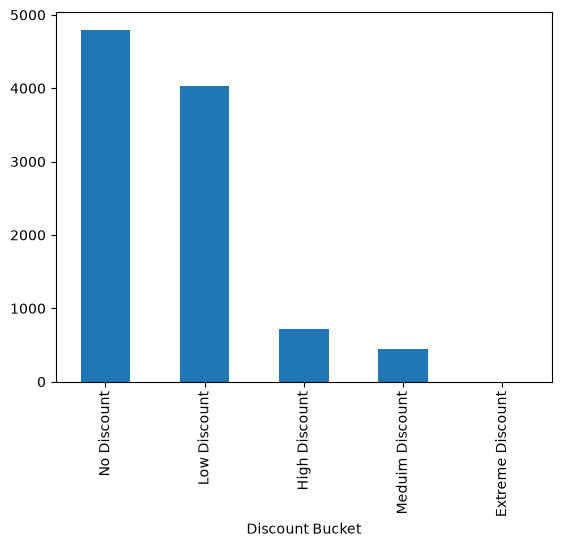

In [263]:
df_clean["Discount Bucket"].value_counts().plot(kind='bar')

In [264]:
df_clean.head(10)

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,...,Order Day of Week,Shipping Duration (Days),Order Quarter,Is Weekend,Unit Price,Profit Margin,Discount Bucket,Shipping Days,Order Weekday,IS Weekend
0,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,130.9800,16.00,No Discount,3,Thursday,False
1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,243.9800,30.00,No Discount,3,Thursday,False
2,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Tuesday,4,2,False,7.3100,47.00,No Discount,4,Tuesday,False
3,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,191.5155,-40.00,Meduim Discount,7,Wednesday,False
4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,11.1840,11.25,Low Discount,7,Wednesday,False
5,CA-2016-115812,2016-06-09,2016-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,...,Thursday,5,2,False,6.9800,29.00,No Discount,5,Thursday,False
6,CA-2016-115812,2016-06-09,2016-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,...,Thursday,5,2,False,1.8200,27.00,No Discount,5,Thursday,False
7,CA-2016-115812,2016-06-09,2016-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,...,Thursday,5,2,False,151.1920,10.00,Low Discount,5,Thursday,False
8,CA-2016-115812,2016-06-09,2016-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,...,Thursday,5,2,False,6.1680,31.25,Low Discount,5,Thursday,False
9,CA-2016-115812,2016-06-09,2016-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,...,Thursday,5,2,False,22.9800,30.00,No Discount,5,Thursday,False


In [265]:
df_clean["Discount"].max()

np.float64(0.8)

In [266]:
df_clean[["Sales", "Quantity", "Unit Price", "Profit", "Profit Margin", "Discount", "Discount Bucket"]].head()

,Sales,Quantity,Unit Price,Profit,Profit Margin,Discount,Discount Bucket
0,261.9600,2,130.9800,41.9136,16.00,0.00,No Discount
1,731.9400,3,243.9800,219.5820,30.00,0.00,No Discount
2,14.6200,2,7.3100,6.8714,47.00,0.00,No Discount
3,957.5775,5,191.5155,-383.0310,-40.00,0.45,Meduim Discount
4,22.3680,2,11.1840,2.5164,11.25,0.20,Low Discount


In [267]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Order ID                  9994 non-null   str           
 1   Order Date                9994 non-null   datetime64[us]
 2   Ship Date                 9994 non-null   datetime64[us]
 3   Ship Mode                 9994 non-null   category      
 4   Customer ID               9994 non-null   str           
 5   Customer Name             9994 non-null   str           
 6   Segment                   9994 non-null   category      
 7   Country/Region            9994 non-null   category      
 8   City                      9994 non-null   str           
 9   State                     9994 non-null   category      
 10  Postal Code               9994 non-null   str           
 11  Region                    9994 non-null   category      
 12  Product ID                9994 

In [268]:
import pandas as pd

df_clean = df_clean.drop_duplicates()

cols_to_drop = ['Row ID', 'Unnamed: 0']
df_clean = df_clean.drop(columns=[c for c in cols_to_drop if c in df_clean.columns], errors='ignore')

df_clean['Order Date'] = pd.to_datetime(df_clean['Order Date'])
df_clean['Ship Date'] = pd.to_datetime(df_clean['Ship Date'])

category_columns = [
    'Ship Mode', 'Segment', 'Country/Region', 'State', 
    'Region', 'Category', 'Sub-Category', 'Discount Bucket'
]
for col in category_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype('category')

string_columns = [
    'Order ID', 'Customer ID', 'Customer Name', 'City', 
    'Postal Code', 'Product ID', 'Product Name'
]
for col in string_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(str)

df_clean.info(memory_usage='deep')

<class 'pandas.DataFrame'>
Index: 9993 entries, 0 to 9993
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Order ID                  9993 non-null   str           
 1   Order Date                9993 non-null   datetime64[us]
 2   Ship Date                 9993 non-null   datetime64[us]
 3   Ship Mode                 9993 non-null   category      
 4   Customer ID               9993 non-null   str           
 5   Customer Name             9993 non-null   str           
 6   Segment                   9993 non-null   category      
 7   Country/Region            9993 non-null   category      
 8   City                      9993 non-null   str           
 9   State                     9993 non-null   category      
 10  Postal Code               9993 non-null   str           
 11  Region                    9993 non-null   category      
 12  Product ID                9993 non-n

In [269]:
df_clean["IS Weekend"].value_counts()

IS Weekend
False    7257
True     2736
Name: count, dtype: int64

In [270]:
weekend_sales = df_clean.groupby(
    df_clean["IS Weekend"]
).agg(
    average_sales = ("Sales", "mean")
)
weekend_sales

,average_sales
IS Weekend,
False,229.787880
True,230.025163


In [271]:
df_clean.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,...,Order Day of Week,Shipping Duration (Days),Order Quarter,Is Weekend,Unit Price,Profit Margin,Discount Bucket,Shipping Days,Order Weekday,IS Weekend
0,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,130.9800,16.00,No Discount,3,Thursday,False
1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,243.9800,30.00,No Discount,3,Thursday,False
2,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Tuesday,4,2,False,7.3100,47.00,No Discount,4,Tuesday,False
3,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,191.5155,-40.00,Meduim Discount,7,Wednesday,False
4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,11.1840,11.25,Low Discount,7,Wednesday,False


In [272]:
customer_summary = df_clean.groupby(df_clean["Customer ID"]).agg(
    orders_count = ("Order ID", "nunique"),
    total_sales = ("Sales", "sum"),
    average_order_sales = ("Sales", "mean"),
    median_order_sales = ("Sales", "median"),
    first_order_date = ("Order Date", "min"),
    last_order_date = ("Order Date", "max")
)

customer_summary["Retention Days"] = (customer_summary["last_order_date"] - customer_summary["first_order_date"]).dt.days
customer_summary

,orders_count,total_sales,average_order_sales,median_order_sales,first_order_date,last_order_date,Retention Days
Customer ID,,,,,,,
AA-10315,5,5563.560,505.778182,41.720,2016-03-31,2019-06-29,1185
AA-10375,9,1056.390,70.426000,17.940,2016-04-21,2019-12-11,1329
AA-10480,4,1790.512,149.209333,39.650,2016-05-04,2019-04-15,1076
AA-10645,6,5086.935,282.607500,94.551,2016-06-22,2019-11-05,1231
AB-10015,3,886.156,147.692667,135.346,2016-02-18,2018-11-10,996
...,...,...,...,...,...,...,...
XP-21865,11,2374.658,84.809214,43.452,2016-01-20,2019-11-17,1397
YC-21895,5,5454.350,681.793750,226.997,2016-11-17,2019-12-26,1134
YS-21880,8,6720.444,560.037000,297.290,2017-01-12,2019-12-21,1073


In [273]:
df_clean["Customer ID"].value_counts()

Customer ID
WB-21850    37
MA-17560    34
JL-15835    34
PP-18955    34
JD-15895    32
            ..
JR-15700     1
AO-10810     1
LD-16855     1
CJ-11875     1
RE-19405     1
Name: count, Length: 793, dtype: int64

In [274]:
customer_summary = df_clean.groupby(
    df_clean["Customer ID"]
).agg(
    total_sales = ("Sales", "sum"),
    average_sales = ("Sales", 'mean'),
    order_count = ("Order ID", "nunique"),
    total_profit = ("Profit", "sum"),
    average_discount = ("Discount", "mean")
)
customer_summary

,total_sales,average_sales,order_count,total_profit,average_discount
Customer ID,,,,,
AA-10315,5563.560,505.778182,5,-362.8825,0.090909
AA-10375,1056.390,70.426000,9,277.3824,0.080000
AA-10480,1790.512,149.209333,4,435.8274,0.016667
AA-10645,5086.935,282.607500,6,857.8033,0.063889
AB-10015,886.156,147.692667,3,129.3465,0.066667
...,...,...,...,...,...
XP-21865,2374.658,84.809214,11,621.2300,0.046429
YC-21895,5454.350,681.793750,5,1305.6290,0.075000
YS-21880,6720.444,560.037000,8,1778.2923,0.050000


In [275]:
df_clean["Region"].value_counts()

Region
West       3203
East       2847
Central    2323
South      1620
Name: count, dtype: int64

In [276]:
df_clean.groupby("Region").agg(
    Count_of_Orders = ("Order ID", "nunique"),
    Total_Sales = ("Sales", "sum")
)

,Count_of_Orders,Total_Sales
Region,,
Central,1175,501239.8908
East,1401,678499.8680
South,822,391721.9050
West,1611,725457.8245


In [277]:
df_clean["Discount Bucket"].value_counts()

Discount Bucket
No Discount         4798
Low Discount        4029
High Discount        718
Meduim Discount      448
Extreme Discount       0
Name: count, dtype: int64

In [278]:
# One row per customer: order count, spend, average order value, tenure
customer_features = df_clean.groupby("Customer ID", observed=True).agg(
    order_count=("Order ID", "nunique"),
    total_spend=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    avg_order_value=("Sales", "mean"),
    first_order=("Order Date", "min"),
    last_order=("Order Date", "max"),
)
customer_features.sort_values("Customer ID", ascending=True).head()

,order_count,total_spend,total_profit,avg_order_value,first_order,last_order
Customer ID,,,,,,
AA-10315,5,5563.560,-362.8825,505.778182,2016-03-31,2019-06-29
AA-10375,9,1056.390,277.3824,70.426000,2016-04-21,2019-12-11
AA-10480,4,1790.512,435.8274,149.209333,2016-05-04,2019-04-15
AA-10645,6,5086.935,857.8033,282.607500,2016-06-22,2019-11-05
AB-10015,3,886.156,129.3465,147.692667,2016-02-18,2018-11-10


In [279]:
customer_features.info()

<class 'pandas.DataFrame'>
Index: 793 entries, AA-10315 to ZD-21925
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_count      793 non-null    int64         
 1   total_spend      793 non-null    float64       
 2   total_profit     793 non-null    float64       
 3   avg_order_value  793 non-null    float64       
 4   first_order      793 non-null    datetime64[us]
 5   last_order       793 non-null    datetime64[us]
dtypes: datetime64[us](2), float64(3), int64(1)
memory usage: 49.7 KB


In [280]:
# Tenure = span between a customer's first and last order in this dataset
customer_features["Customer Tenure Days"] = (
    customer_features["last_order"] - customer_features["first_order"]
).dt.days

customer_features.sort_values("Customer Tenure Days", ascending=False).head(10)

,order_count,total_spend,total_profit,avg_order_value,first_order,last_order,Customer Tenure Days
Customer ID,,,,,,,
MM-17920,11,3794.080,82.1250,237.130000,2016-01-13,2019-12-23,1440
DL-13315,8,1458.258,288.8732,85.779882,2016-01-16,2019-12-08,1422
CS-12250,12,2754.216,738.3626,98.364857,2016-01-13,2019-12-04,1421
ND-18370,9,4326.139,353.6455,240.341056,2016-01-13,2019-12-03,1420
MV-17485,9,1560.050,189.0258,104.003333,2016-01-20,2019-12-03,1413
GA-14725,11,1398.382,136.7079,63.562818,2016-02-11,2019-12-25,1413
ME-17320,10,10663.728,1859.4695,484.714909,2016-01-06,2019-11-18,1412
BS-11590,6,2454.928,381.7807,245.492800,2016-01-14,2019-11-25,1411
MV-18190,7,1734.574,273.8582,157.688545,2016-01-30,2019-12-11,1411


In [281]:
# One row per product: units sold, revenue, average discount given
product_features = df_clean.groupby("Product ID", observed=True).agg(
    total_qty_sold=("Quantity", "sum"),
    total_revenue=("Sales", "sum"),
    avg_discount=("Discount", "mean"),
).sort_values("total_revenue", ascending=False)

product_features.head()

,total_qty_sold,total_revenue,avg_discount
Product ID,,,
TEC-CO-10004722,20,61599.824,0.12
OFF-BI-10003527,31,27453.384,0.24
TEC-MA-10002412,6,22638.480,0.50
FUR-CH-10002024,39,21870.576,0.20
OFF-BI-10001359,37,19823.479,0.30


In [282]:
df_clean.groupby("Customer ID").agg(
    last_order_date = ("Order Date", "max")
)

,last_order_date
Customer ID,
AA-10315,2019-06-29
AA-10375,2019-12-11
AA-10480,2019-04-15
AA-10645,2019-11-05
AB-10015,2018-11-10
...,...
XP-21865,2019-11-17
YC-21895,2019-12-26
YS-21880,2019-12-21


In [283]:
df_clean["Order Date"].min()

Timestamp('2016-01-03 00:00:00')

In [284]:
df_clean["Customer ID"].nunique()

793

In [285]:

recency_reference = df_clean["Order Date"].max() + pd.Timedelta(days=1)

rfm = df_clean.groupby("Customer ID").agg(
    monetary_value = ("Sales", "sum"),
    frequency = ("Order ID", "nunique"),
    recency = ("Order Date", lambda x: (recency_reference - x.max()).days)
)

display(rfm.sort_values("recency", ascending=True).head())

,monetary_value,frequency,recency
Customer ID,,,
JM-15580,303.948,5,1
PO-18865,2493.214,7,1
CC-12430,2870.050,10,1
EB-13975,1643.255,4,1
KH-16360,3100.612,6,2


In [286]:
recency_reference = df_clean["Order Date"].max() + pd.Timedelta(days=1)
recency_reference

Timestamp('2019-12-31 00:00:00')

In [287]:
fixed_date = df_clean["Order Date"].max() + pd.Timedelta(days=1)
fixed_date

Timestamp('2019-12-31 00:00:00')

In [288]:
rfm_model_1 = df_clean.groupby("Customer ID").agg(
    monetary = ("Sales", "sum"),
    frequency = ("Order ID", "nunique"),
    recency = ("Order Date", lambda x: (fixed_date - x.max()).days)
)

rfm_model_1

,monetary,frequency,recency
Customer ID,,,
AA-10315,5563.560,5,185
AA-10375,1056.390,9,20
AA-10480,1790.512,4,260
AA-10645,5086.935,6,56
AB-10015,886.156,3,416
...,...,...,...
XP-21865,2374.658,11,44
YC-21895,5454.350,5,5
YS-21880,6720.444,8,10


In [289]:
reference_date = df_clean["Order Date"].max() + pd.Timedelta(days=1)
reference_date

Timestamp('2019-12-31 00:00:00')

In [290]:
df_clean.head().sort_values("Order ID")

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,...,Order Day of Week,Shipping Duration (Days),Order Quarter,Is Weekend,Unit Price,Profit Margin,Discount Bucket,Shipping Days,Order Weekday,IS Weekend
2,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Tuesday,4,2,False,7.3100,47.00,No Discount,4,Tuesday,False
0,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,130.9800,16.00,No Discount,3,Thursday,False
1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Thursday,3,4,False,243.9800,30.00,No Discount,3,Thursday,False
3,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,191.5155,-40.00,Meduim Discount,7,Wednesday,False
4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Wednesday,7,4,False,11.1840,11.25,Low Discount,7,Wednesday,False


In [291]:
# R - reference_date - last_order_date
# F - Unique count of Order ID for each customer
# M - Sum of Sales for each customer

rfm_model = df_clean.groupby("Customer ID").agg(
    recency = ("Order Date", lambda x: (reference_date - x.max()).days),
    frequency = ("Order ID", "nunique"),
    monetary = ("Sales", "sum")
)

rfm_model.sort_values("monetary", ascending=False)

,recency,frequency,monetary
Customer ID,,,
SM-20320,80,5,25043.050
TC-20980,400,5,19052.218
RB-19360,97,6,15117.339
TA-21385,70,4,14595.620
AB-10105,42,10,14473.571
...,...,...,...
RS-19870,20,2,22.328
MG-18205,265,1,16.739
CJ-11875,366,1,16.520


In [292]:
# RFM: Recency (days since last order), Frequency (distinct orders),
# Monetary (total Sales). Recency is measured against the day after the
# last order in the whole dataset, since we have no "today" to measure from.
snapshot_date = df_clean["Order Date"].max() + pd.Timedelta(days=1)
snapshot_date

Timestamp('2019-12-31 00:00:00')

In [293]:
# using the parameter observed=True should ensure that if we have empty category it will be shown with the zero value
rfm = df_clean.groupby("Customer ID", observed=True).agg(
    # how can we interpret the lambda thing?
    # lambda: this is the function name that we are going to create for this specific purpose
    # for each x in the order date for each customer id this x will equal to
    # the snapshot_date - the maximum order date and then we are going to calculate
    # the number of days between both dates
    Recency=("Order Date", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum"),
)

rfm.sort_values("Monetary", ascending=False).head()

,Recency,Frequency,Monetary
Customer ID,,,
SM-20320,80,5,25043.050
TC-20980,400,5,19052.218
RB-19360,97,6,15117.339
TA-21385,70,4,14595.620
AB-10105,42,10,14473.571


In [294]:
# This where we are going to calculate the last date in the dataset 
# We are goingt to add an extra day to fix the today date!
last_date = df_clean["Order Date"].max() + pd.Timedelta(days=1)
last_date

Timestamp('2019-12-31 00:00:00')

In [295]:
rfm_amended = df_clean.groupby("Customer ID").agg(
    recency = ("Order Date", lambda x: (last_date - x.max()).days),
    frequency = ("Order ID", "nunique"),
    monetary = ("Sales", "sum")
)

rfm_amended

,recency,frequency,monetary
Customer ID,,,
AA-10315,185,5,5563.560
AA-10375,20,9,1056.390
AA-10480,260,4,1790.512
AA-10645,56,6,5086.935
AB-10015,416,3,886.156
...,...,...,...
XP-21865,44,11,2374.658
YC-21895,5,5,5454.350
YS-21880,10,8,6720.444


In [296]:

print("--- Feature Validation Results ---")

inf_count = np.isinf(df_clean["Unit Price"]).sum()
print(f"Infinite values in Unit Price: {inf_count}")

negative_shipping = (df_clean["Shipping Duration (Days)"] < 0).sum()
print(f"Negative shipping durations: {negative_shipping}")

null_buckets = df_clean["Discount Bucket"].isnull().sum()
print(f"Unlabeled Discount Buckets (NaN): {null_buckets}")

--- Feature Validation Results ---
Infinite values in Unit Price: 0
Negative shipping durations: 0
Unlabeled Discount Buckets (NaN): 0


In [297]:
np.isinf(df_clean["Unit Price"]).sum()

np.int64(0)

In [298]:
df_clean["Sales"]/df_clean["Quantity"]

0       130.9800
1       243.9800
2         7.3100
3       191.5155
4        11.1840
          ...   
9989      8.4160
9990     45.9800
9991    129.2880
9992      7.4000
9993    121.5800
Length: 9993, dtype: float64

In [299]:
print("Infinite Unit Price values:", np.isinf(df_clean["Unit Price"]).sum())
print("Infinite Profit Margin values:", np.isinf(df_clean["Profit Margin"]).sum())


Infinite Unit Price values: 0
Infinite Profit Margin values: 0


In [300]:
print("Shipping Days range:", df_clean["Shipping Days"].min(), "to", df_clean["Shipping Days"].max())
print("Negative Shipping Days:", (df_clean["Shipping Days"] < 0).sum())


Shipping Days range: 0 to 7
Negative Shipping Days: 0


In [301]:
print("Unlabeled Discount Bucket rows:", df_clean["Discount Bucket"].isnull().sum())

Unlabeled Discount Bucket rows: 0


In [302]:
print(df_clean["Discount Bucket"].value_counts())
print()
print(df_clean["Shipping Days"].describe())
print()
print(df_clean["Profit Margin"].describe())

Discount Bucket
No Discount         4798
Low Discount        4029
High Discount        718
Meduim Discount      448
Extreme Discount       0
Name: count, dtype: int64

count    9993.000000
mean        3.958071
std         1.748024
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping Days, dtype: float64

count    9993.000000
mean       12.033026
std        46.677485
min      -275.000000
25%         7.500000
50%        27.000000
75%        36.250000
max        50.000000
Name: Profit Margin, dtype: float64


In [303]:
df_clean["Discount Bucket"].value_counts()

Discount Bucket
No Discount         4798
Low Discount        4029
High Discount        718
Meduim Discount      448
Extreme Discount       0
Name: count, dtype: int64

In [304]:
print(df_clean.groupby("Discount Bucket")["Profit"].mean())

Discount Bucket
No Discount         66.900292
Low Discount        22.444342
Meduim Discount   -121.411568
High Discount      -98.348741
Name: Profit, dtype: float64


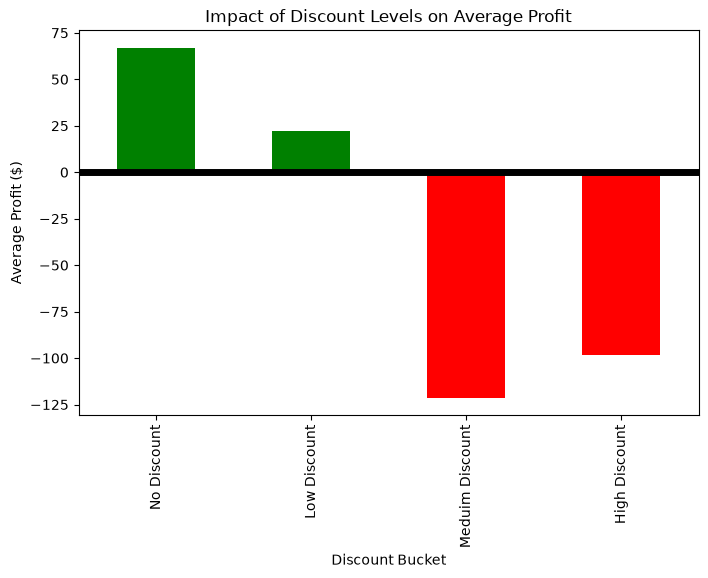

In [305]:
colors = ['green', 'green', 'red', 'red']
df_clean.groupby("Discount Bucket", observed=True)["Profit"].mean().plot(kind='bar', color=colors, figsize=(8, 5))

plt.title("Impact of Discount Levels on Average Profit")
plt.ylabel("Average Profit ($)")
plt.axhline(0, color='black', linewidth=5) 
plt.show()

In [306]:
monthly_sales = df_clean.groupby("Order Month")["Sales"].sum()
monthly_sales.reindex(month_order).plot(kind='line', figsize=(10, 5), marker='o')

plt.title("Total Sales Seasonality by Month", fontweight='bold')
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.ylim(bottom=0)
plt.grid(axis='y', linestyle='--', alpha=0.7) 
plt.xticks(rotation=45)
plt.show()

NameError: name 'month_order' is not defined

In [ ]:
region_summary = df_clean.groupby("Region", observed=True)[["Sales", "Profit"]].sum().sort_values("Profit", ascending=False)
region_summary

,Sales,Profit
Region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
South,391721.9050,46749.4303
Central,501239.8908,39706.3625


In [ ]:
category_summary = df_clean.groupby("Category", observed=True).agg(
    total_sales=("Sales", "sum"),
    avg_profit=("Profit", "mean"),
    orders=("Order ID", "count"),
)
category_summary

,total_sales,avg_profit,orders
Category,,,
Furniture,741999.7953,8.699327,2121
Office Supplies,719047.0320,20.327050,6026
Technology,836154.0330,78.752002,1847


In [ ]:
pivot = pd.pivot_table(
    df_clean,
    values="Sales",
    index="Region",
    columns="Category",
    aggfunc="mean",
    observed=True,
)
pivot

Category,Furniture,Office Supplies,Technology
Region,,,
Central,340.534644,117.458801,405.753124
East,346.574383,120.044425,495.278469
South,353.309289,126.282727,507.753952
West,357.302325,116.422377,420.687533


In [ ]:
print("--- Q3: Ship Mode Analysis ---")
ship_analysis = df_clean.groupby("Ship Mode", observed=True).agg(
    Avg_Shipping_Days=("Shipping Duration (Days)", "mean"),
    Avg_Profit=("Profit", "mean")
)
display(ship_analysis.round(2))

--- Q3: Ship Mode Analysis ---


,Avg_Shipping_Days,Avg_Profit
Ship Mode,,
First Class,2.18,31.84
Same Day,0.04,29.27
Second Class,3.24,29.54
Standard Class,5.01,27.49



--- Q4: Sales Seasonality ---


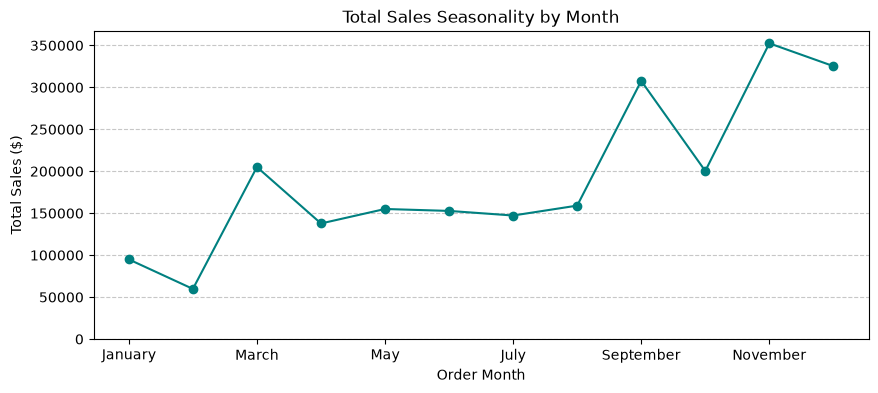

In [ ]:
print("\n--- Q4: Sales Seasonality ---")
month_order = ["January", "February", "March", "April", "May", "June", 
               "July", "August", "September", "October", "November", "December"]

monthly_sales = df_clean.groupby("Order Month", observed=True)["Sales"].sum().reindex(month_order)

plt.figure(figsize=(10, 4))
monthly_sales.plot(kind='line', marker='o', color='teal')
plt.title("Total Sales Seasonality by Month")
plt.ylabel("Total Sales ($)")
plt.ylim(bottom=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
print("\n--- Q5: Most Valuable Customers (Top 5 by Monetary Value) ---")
top_customers = rfm_model.sort_values("monetary", ascending=False).head(5)
display(top_customers)


--- Q5: Most Valuable Customers (Top 5 by Monetary Value) ---


,recency,frequency,monetary
Customer ID,,,
SM-20320,80,5,25043.050
TC-20980,400,5,19052.218
RB-19360,97,6,15117.339
TA-21385,70,4,14595.620
AB-10105,42,10,14473.571


<Axes: xlabel='Discount Bucket'>

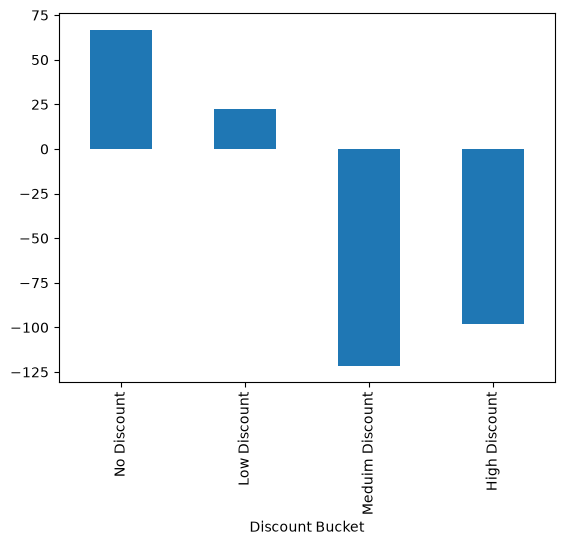

In [ ]:
discount_profit = df_clean.groupby("Discount Bucket", observed=True)["Profit"].mean()
discount_profit.plot(kind='bar')

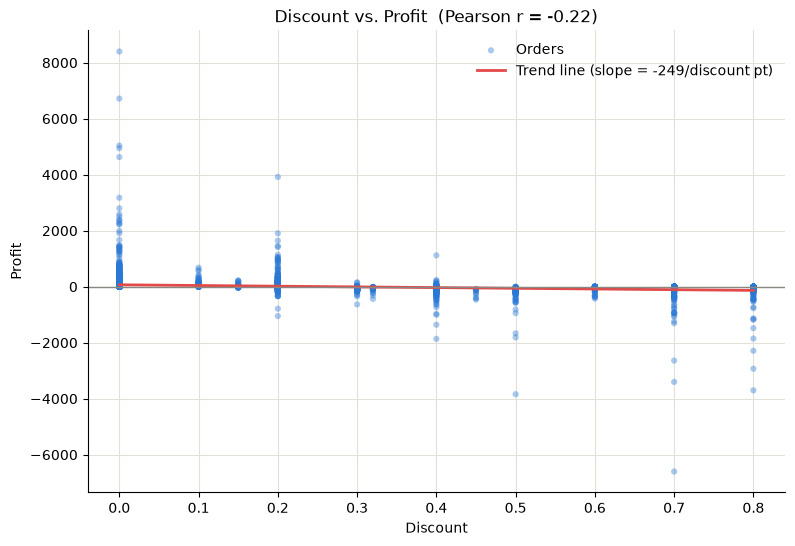

Pearson correlation (Discount, Profit): -0.219 -- a weak negative linear relationship.


In [ ]:
# Here, I need to plot a scatter plot between the discount and the profit 
# Check the line between both of them

correlation = df_clean["Discount"].corr(df_clean["Profit"])

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    df_clean["Discount"], df_clean["Profit"],
    color="#2a78d6", alpha=0.4, s=20, edgecolors="none", label="Orders",
)

trend_coeffs = np.polyfit(df_clean["Discount"], df_clean["Profit"], deg=1)
trend_line = np.poly1d(trend_coeffs)
x_trend = np.linspace(df_clean["Discount"].min(), df_clean["Discount"].max(), 100)
ax.plot(
    x_trend, trend_line(x_trend),
    color="#e34948", linewidth=2, label=f"Trend line (slope = {trend_coeffs[0]:.0f}/discount pt)",
)

ax.axhline(0, color="#898781", linewidth=1)
ax.set_xlabel("Discount")
ax.set_ylabel("Profit")
ax.set_title(f"Discount vs. Profit  (Pearson r = {correlation:.2f})")
ax.grid(True, color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.show()

strength = (
    "strong" if abs(correlation) >= 0.5 else
    "moderate" if abs(correlation) >= 0.3 else
    "weak" if abs(correlation) >= 0.1 else
    "negligible"
)
direction = "negative" if correlation < 0 else "positive"
print(f"Pearson correlation (Discount, Profit): {correlation:.3f} -- a {strength} {direction} linear relationship.")

In [ ]:
ship_mode_summary = df_clean.groupby("Ship Mode", observed=True).agg(
    avg_profit=("Profit", "mean"),
    avg_shipping_days=("Shipping Days", "mean"),
)
ship_mode_summary

,avg_profit,avg_shipping_days
Ship Mode,,
First Class,31.839948,2.182705
Same Day,29.266591,0.044199
Second Class,29.535545,3.237532
Standard Class,27.494770,5.006535


(0.0, 367096.56198)

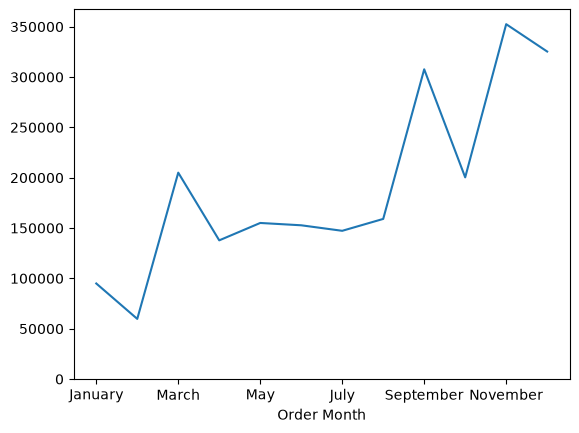

In [ ]:
week_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_clean.groupby("Order Month", observed=True)["Sales"].sum().reindex(month_order).plot(kind='line')
plt.ylim(bottom=0)


(0.0, 405465.006295)

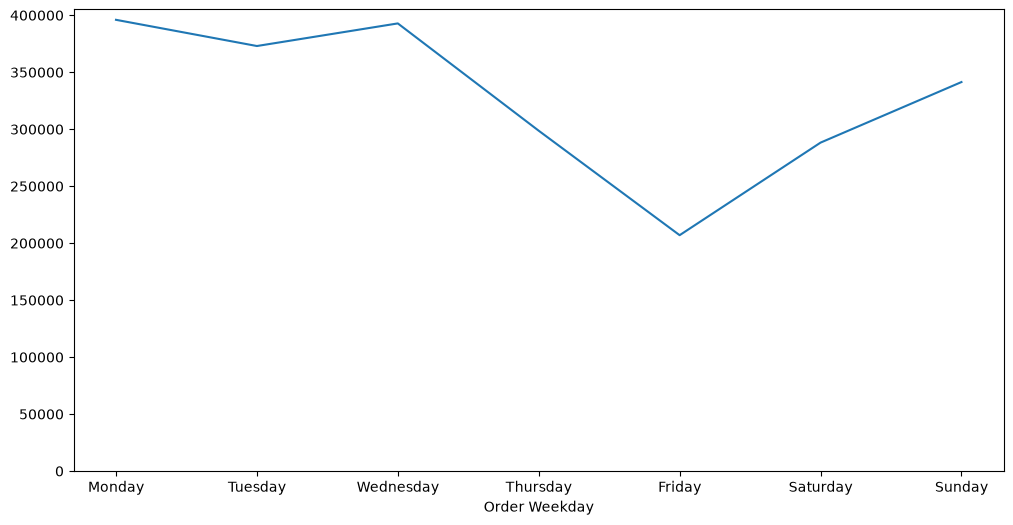

In [ ]:
df_clean.groupby("Order Weekday", observed=True)["Sales"].sum().sort_values(ascending=False).reindex(week_order).plot(kind='line', figsize=(12,6))
plt.ylim(bottom=0)

In [ ]:
rfm.sort_values("Monetary", ascending=False).head(10)

,Recency,Frequency,Monetary
Customer ID,,,
SM-20320,80,5,25043.050
TC-20980,400,5,19052.218
RB-19360,97,6,15117.339
TA-21385,70,4,14595.620
AB-10105,42,10,14473.571
KL-16645,48,12,14175.229
SC-20095,350,9,14142.334
HL-15040,44,6,12873.298
SE-20110,10,11,12209.438


In [ ]:
handoff_manifest = {
    "df_clean": "row-level cleaned + feature-engineered DataFrame",
    "customer_features": "one row per Customer ID -- spend, order count, tenure",
    "product_features": "one row per Product ID -- units sold, revenue, avg discount",
    "rfm": "one row per Customer ID -- Recency, Frequency, Monetary",
    "state_profit": "total Profit per State",
    "discount_profit": "average Profit per Discount Bucket",
    "ship_mode_summary": "average Profit and Shipping Days per Ship Mode",
    "region_summary": "total Sales and Profit per Region",
    "category_summary": "total Sales, avg Profit, order count per Category",
    "pivot": "average Sales by Region x Category",
}
for name, description in handoff_manifest.items():
    print(f"{name}: {description}")

df_clean: row-level cleaned + feature-engineered DataFrame
customer_features: one row per Customer ID -- spend, order count, tenure
product_features: one row per Product ID -- units sold, revenue, avg discount
rfm: one row per Customer ID -- Recency, Frequency, Monetary
state_profit: total Profit per State
discount_profit: average Profit per Discount Bucket
ship_mode_summary: average Profit and Shipping Days per Ship Mode
region_summary: total Sales and Profit per Region
category_summary: total Sales, avg Profit, order count per Category
pivot: average Sales by Region x Category


In [ ]:
handoff_manifest = {
    "df_clean": "row-level cleaned + feature-engineered DataFrame",
    "customer_features": "one row per Customer ID -- spend, order count, tenure",
    "product_features": "one row per Product ID -- units sold, revenue, avg discount",
    "rfm": "one row per Customer ID -- Recency, Frequency, Monetary",
    "state_profit": "total Profit per State",
    "discount_profit": "average Profit per Discount Bucket",
    "ship_mode_summary": "average Profit and Shipping Days per Ship Mode",
    "region_summary": "total Sales and Profit per Region",
    "category_summary": "total Sales, avg Profit, order count per Category",
    "pivot": "average Sales by Region x Category",
}
for name, description in handoff_manifest.items():
    print(f"{name}: {description}")

df_clean: row-level cleaned + feature-engineered DataFrame
customer_features: one row per Customer ID -- spend, order count, tenure
product_features: one row per Product ID -- units sold, revenue, avg discount
rfm: one row per Customer ID -- Recency, Frequency, Monetary
state_profit: total Profit per State
discount_profit: average Profit per Discount Bucket
ship_mode_summary: average Profit and Shipping Days per Ship Mode
region_summary: total Sales and Profit per Region
category_summary: total Sales, avg Profit, order count per Category
pivot: average Sales by Region x Category


In [ ]:
customer_features

,order_count,total_spend,total_profit,avg_order_value,first_order,last_order,Customer Tenure Days
Customer ID,,,,,,,
AA-10315,5,5563.560,-362.8825,505.778182,2016-03-31,2019-06-29,1185
AA-10375,9,1056.390,277.3824,70.426000,2016-04-21,2019-12-11,1329
AA-10480,4,1790.512,435.8274,149.209333,2016-05-04,2019-04-15,1076
AA-10645,6,5086.935,857.8033,282.607500,2016-06-22,2019-11-05,1231
AB-10015,3,886.156,129.3465,147.692667,2016-02-18,2018-11-10,996
...,...,...,...,...,...,...,...
XP-21865,11,2374.658,621.2300,84.809214,2016-01-20,2019-11-17,1397
YC-21895,5,5454.350,1305.6290,681.793750,2016-11-17,2019-12-26,1134
YS-21880,8,6720.444,1778.2923,560.037000,2017-01-12,2019-12-21,1073


In [ ]:
product_features

,total_qty_sold,total_revenue,avg_discount
Product ID,,,
TEC-CO-10004722,20,61599.824,0.12
OFF-BI-10003527,31,27453.384,0.24
TEC-MA-10002412,6,22638.480,0.50
FUR-CH-10002024,39,21870.576,0.20
OFF-BI-10001359,37,19823.479,0.30
...,...,...,...
OFF-AR-10003986,2,7.700,0.00
OFF-EN-10001535,2,7.072,0.20
OFF-PA-10000048,1,6.480,0.00


In [ ]:
rfm

,Recency,Frequency,Monetary
Customer ID,,,
AA-10315,185,5,5563.560
AA-10375,20,9,1056.390
AA-10480,260,4,1790.512
AA-10645,56,6,5086.935
AB-10015,416,3,886.156
...,...,...,...
XP-21865,44,11,2374.658
YC-21895,5,5,5454.350
YS-21880,10,8,6720.444


In [ ]:

# 1. state_profit
state_profit = df_clean.groupby("State", observed=True)["Profit"].sum().sort_values(ascending=False)

# 2. discount_profit
discount_profit = df_clean.groupby("Discount Bucket", observed=True)["Profit"].mean()

# 3. ship_mode_summary
ship_mode_summary = df_clean.groupby("Ship Mode", observed=True).agg(
    Avg_Shipping_Days=("Shipping Duration (Days)", "mean"),
    Avg_Profit=("Profit", "mean")
)

# 4. region_summary
region_summary = df_clean.groupby("Region", observed=True)[["Sales", "Profit"]].sum().sort_values("Profit", ascending=False)

# 5. category_summary
category_summary = df_clean.groupby("Category", observed=True).agg(
    total_sales=("Sales", "sum"),
    avg_profit=("Profit", "mean"),
    orders=("Order ID", "count")
)

# 6. pivot (Region vs Category Profit)
pivot = df_clean.pivot_table(
    values="Profit", 
    index="Region", 
    columns="Category", 
    aggfunc="sum",
    margins=True,
    margins_name="Total"
)

print("Summary tables are ready for export!")

Summary tables are ready for export!


In [ ]:
import os

export_dir = "handoff_data"
os.makedirs(export_dir, exist_ok=True)

# Row-level / per-entity tables -- Parquet preserves dtypes
df_clean.to_parquet(f"{export_dir}/df_clean.parquet", engine="pyarrow")
customer_features.to_parquet(f"{export_dir}/customer_features.parquet", engine="pyarrow")
product_features.to_parquet(f"{export_dir}/product_features.parquet", engine="pyarrow")
rfm.to_parquet(f"{export_dir}/rfm.parquet", engine="pyarrow")

# Small, chart-ready summary tables -- CSV is sufficient
state_profit.to_csv(f"{export_dir}/state_profit.csv")
discount_profit.to_csv(f"{export_dir}/discount_profit.csv")
ship_mode_summary.to_csv(f"{export_dir}/ship_mode_summary.csv")
region_summary.to_csv(f"{export_dir}/region_summary.csv")
category_summary.to_csv(f"{export_dir}/category_summary.csv")
pivot.to_csv(f"{export_dir}/pivot_region_category.csv")

print(f"Exported {len(os.listdir(export_dir))} files to '{export_dir}/':")
for filename in sorted(os.listdir(export_dir)):
    print(f"  {filename}")

Exported 10 files to 'handoff_data/':
  category_summary.csv
  customer_features.parquet
  df_clean.parquet
  discount_profit.csv
  pivot_region_category.csv
  product_features.parquet
  region_summary.csv
  rfm.parquet
  ship_mode_summary.csv
  state_profit.csv


In [ ]:
state_profit

State
California              76381.3871
New York                74038.5486
Washington              33402.6517
Michigan                24463.1876
Virginia                18597.9504
Indiana                 18382.9363
Georgia                 16250.0433
Kentucky                11199.6966
Minnesota               10823.1874
Delaware                 9977.3748
New Jersey               9772.9138
Wisconsin                8401.8004
Rhode Island             7285.6293
Maryland                 7031.1788
Massachusetts            6785.5016
Missouri                 6436.2105
Alabama                  5786.8253
Oklahoma                 4853.9560
Arkansas                 4008.6871
Connecticut              3511.4918
Nevada                   3316.7659
Mississippi              3172.9762
Utah                     2546.5335
Vermont                  2244.9783
Louisiana                2196.1023
Nebraska                 2037.0942
Montana                  1833.3285
South Carolina           1769.0566
New Hampshire 